In [1]:
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split

from feature_engineering import TARGET_CLF, TARGET_REG, FeatureEngineer, build_pipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

DATA_PATH = "emi_dataset.csv"      # <- cleaned dataset from Member 1
RANDOM_STATE = 42
os.makedirs("visuals", exist_ok=True)
os.makedirs("reports", exist_ok=True)

insights = []                      # collected automatically, used in the report
charts = []                        # (title, file) pairs, used in the report

def save(name, title):
    path = f"visuals/{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    charts.append((title, path))
    plt.show()

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_"))

# numbers stored as text -> numeric
for c in df.select_dtypes("object").columns:
    df[c] = df[c].astype(str).str.strip().replace({"nan": np.nan, "": np.nan})
    as_num = pd.to_numeric(df[c], errors="coerce")
    if as_num.notna().mean() > 0.9 and c != TARGET_CLF:
        df[c] = as_num

assert TARGET_CLF in df.columns and TARGET_REG in df.columns, (
    f"Dataset must contain '{TARGET_CLF}' and '{TARGET_REG}'. Your columns: {list(df.columns)}")

n_raw = len(df)
n_dup = int(df.duplicated().sum())
df = df.drop_duplicates().dropna(subset=[TARGET_CLF, TARGET_REG]).reset_index(drop=True)
n_missing = int(df.isna().sum().sum())

insights.append(f"The dataset has {len(df):,} records and {df.shape[1]} columns "
                f"({n_dup:,} duplicates removed, {n_missing:,} missing cells handled later by the pipeline's imputers).")
print("Shape:", df.shape)
df.head()

Shape: (400000, 27)


,age,gender,marital_status,education,monthly_salary,employment_type,years_of_employment,company_type,house_type,monthly_rent,family_size,dependents,school_fees,college_fees,travel_expenses,groceries_utilities,other_monthly_expenses,existing_loans,current_emi_amount,credit_score,bank_balance,emergency_fund,emi_scenario,requested_amount,requested_tenure,max_monthly_emi,emi_eligibility
0,49,Male,Married,Professional,107819.0,Private,8,Startup,Rented,19006,2,1,2622,6611,586,20645,5945,Yes,22494,544,151503,28325,E-commerce,17841,14,12954.0,High_Risk
1,25,Female,Married,Graduate,17174.0,Self-employed,30,Government,Rented,33333,7,4,8467,10735,7029,5419,6630,Yes,9328,332,149564,33320,E-commerce,63526,12,500.0,Not_Eligible
2,43,Male,Single,High School,197437.0,Private,27,Government,Rented,18866,6,2,12882,4684,2720,6062,10333,No,0,572,44400,162985,E-commerce,133258,20,50000.0,High_Risk
3,46,Female,Married,Post Graduate,120058.0,Private,34,Government,Family,0,5,3,8579,12343,4741,24660,8689,Yes,2099,618,251787,73215,Home_Appliances,279058,10,27909.0,High_Risk
4,31,Female,Single,Graduate,148448.0,Government,20,Government,Family,0,4,0,10684,8413,5558,3928,9956,No,0,334,328035,87330,Personal_Loan,422780,36,35011.0,High_Risk


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400000 entries, 0 to 399999
Data columns (total 27 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   age                     400000 non-null  int64  
 1   gender                  400000 non-null  object 
 2   marital_status          400000 non-null  object 
 3   education               400000 non-null  object 
 4   monthly_salary          396000 non-null  float64
 5   employment_type         400000 non-null  object 
 6   years_of_employment     400000 non-null  int64  
 7   company_type            400000 non-null  object 
 8   house_type              400000 non-null  object 
 9   monthly_rent            400000 non-null  int64  
 10  family_size             400000 non-null  int64  
 11  dependents              400000 non-null  int64  
 12  school_fees             400000 non-null  int64  
 13  college_fees            400000 non-null  int64  
 14  travel_expenses     

In [4]:
display(df.describe().T)
miss = df.isna().sum()
display(miss[miss > 0].to_frame("missing_values"))

,count,mean,std,min,25%,50%,75%,max
age,400000.0,42.492198,10.383378,25.0,33.00,42.0,51.00,60.0
monthly_salary,396000.0,107596.299732,53373.050677,15000.0,61403.75,107678.0,153850.25,200000.0
years_of_employment,400000.0,17.009095,10.105663,0.0,8.00,17.0,26.00,34.0
monthly_rent,400000.0,8597.009630,12507.885667,0.0,0.00,0.0,16867.00,39999.0
family_size,400000.0,3.999730,1.998705,1.0,2.00,4.0,6.00,7.0
dependents,400000.0,2.001508,1.415237,0.0,1.00,2.0,3.00,4.0
school_fees,400000.0,7505.852450,4326.725824,0.0,3766.00,7514.0,11248.00,14999.0
college_fees,400000.0,12482.510480,7217.644040,0.0,6223.00,12461.0,18742.00,24999.0
travel_expenses,400000.0,5250.903495,2741.765280,500.0,2878.00,5253.0,7622.00,9999.0
groceries_utilities,400000.0,13490.212998,6643.600103,2000.0,7737.75,13473.0,19246.00,24999.0


,missing_values
monthly_salary,4000


## 2.2 Target variables

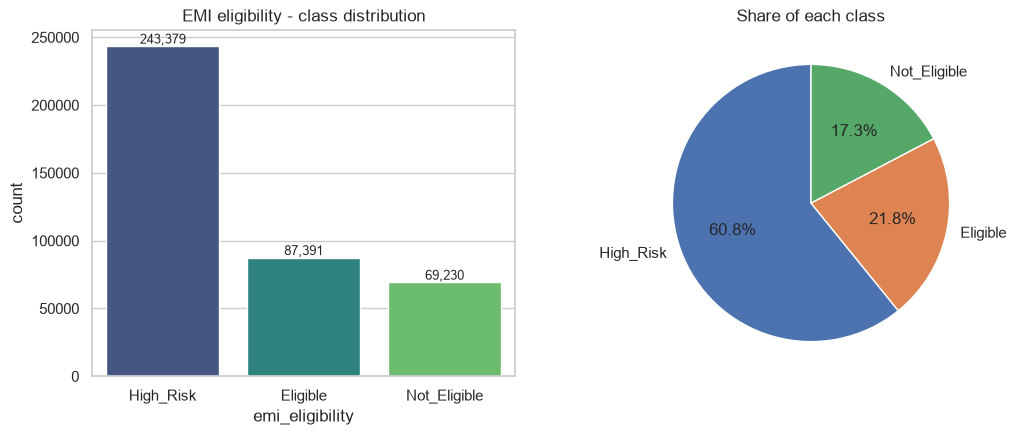

,percent
emi_eligibility,
High_Risk,60.8
Eligible,21.8
Not_Eligible,17.3


In [5]:
counts = df[TARGET_CLF].value_counts()
pct = (counts / counts.sum() * 100).round(1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=df, x=TARGET_CLF, order=counts.index, palette="viridis", ax=ax[0])
ax[0].set_title("EMI eligibility - class distribution")
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontsize=9)
ax[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Share of each class")
save("01_target_distribution", "EMI eligibility class distribution")

imbalanced = pct.max() > 55
insights.append("Class balance: " + ", ".join(f"{k} = {v}%" for k, v in pct.items()) + ". "
                + ("The classes are imbalanced, so classifiers should use class weights and be judged on F1 / recall, not accuracy alone."
                   if imbalanced else "The classes are reasonably balanced."))
display(pct.to_frame("percent"))

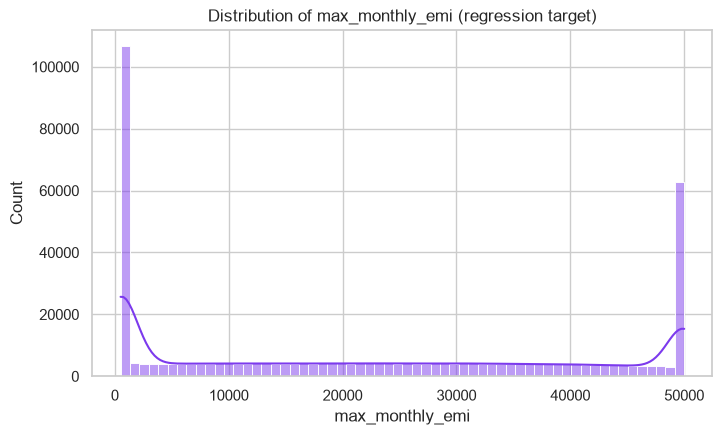

In [6]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df[TARGET_REG], bins=60, kde=True, color="#7c3aed")
plt.title("Distribution of max_monthly_emi (regression target)")
save("02_max_emi_distribution", "Distribution of max monthly EMI")

insights.append(f"max_monthly_emi ranges from {df[TARGET_REG].min():,.0f} to {df[TARGET_REG].max():,.0f} "
                f"(median {df[TARGET_REG].median():,.0f}, mean {df[TARGET_REG].mean():,.0f}, skew {df[TARGET_REG].skew():.2f}).")

## 2.3 Eligibility patterns across the 5 EMI scenarios

emi_eligibility,Eligible,High_Risk,Not_Eligible
emi_scenario,,,
E-commerce,23.5,61.0,15.5
Education,22.2,60.9,17.0
Home_Appliances,23.7,60.9,15.4
Personal_Loan,20.9,60.6,18.5
Vehicle,19.0,60.8,20.2


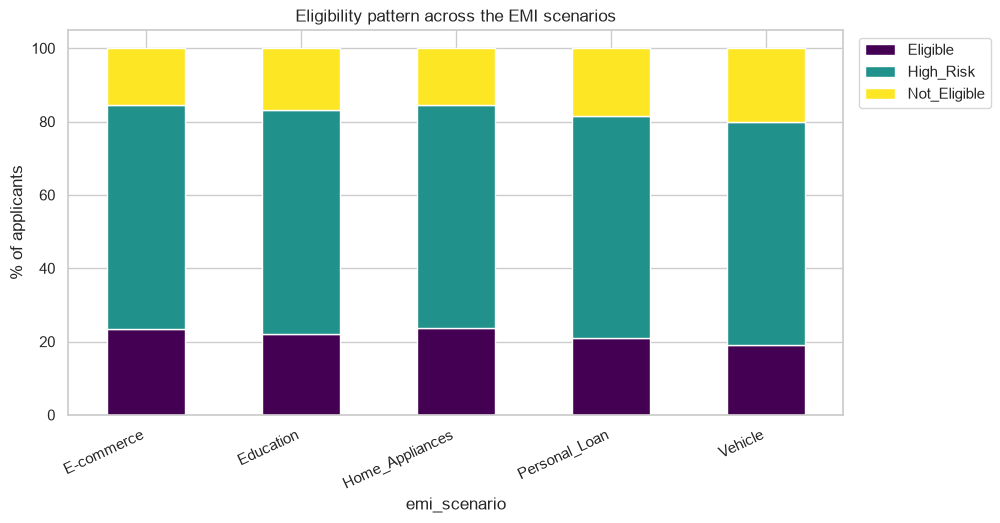

,requested_amount,requested_tenure,max_monthly_emi
emi_scenario,,,
E-commerce,105163.0,14.0,20187.0
Education,275697.0,27.0,20268.0
Home_Appliances,160048.0,21.0,19956.0
Personal_Loan,525733.0,36.0,20109.0
Vehicle,786562.0,48.0,19812.0


In [7]:
if "emi_scenario" in df.columns:
    ct = pd.crosstab(df["emi_scenario"], df[TARGET_CLF], normalize="index") * 100
    display(ct.round(1))
    ct.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="viridis")
    plt.ylabel("% of applicants")
    plt.title("Eligibility pattern across the EMI scenarios")
    plt.xticks(rotation=25, ha="right")
    plt.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")
    save("03_eligibility_by_scenario", "Eligibility by EMI scenario")

    top_class = df[TARGET_CLF].value_counts().index[0]
    best, worst = ct[top_class].idxmax(), ct[top_class].idxmin()
    insights.append(f"Eligibility differs by scenario: '{best}' has the highest share of {top_class} "
                    f"({ct.loc[best, top_class]:.1f}%) and '{worst}' the lowest ({ct.loc[worst, top_class]:.1f}%).")

    req = [c for c in ("requested_amount", "requested_tenure", TARGET_REG) if c in df.columns]
    display(df.groupby("emi_scenario")[req].median().round(0))
else:
    print("No 'emi_scenario' column found - update the column name above.")

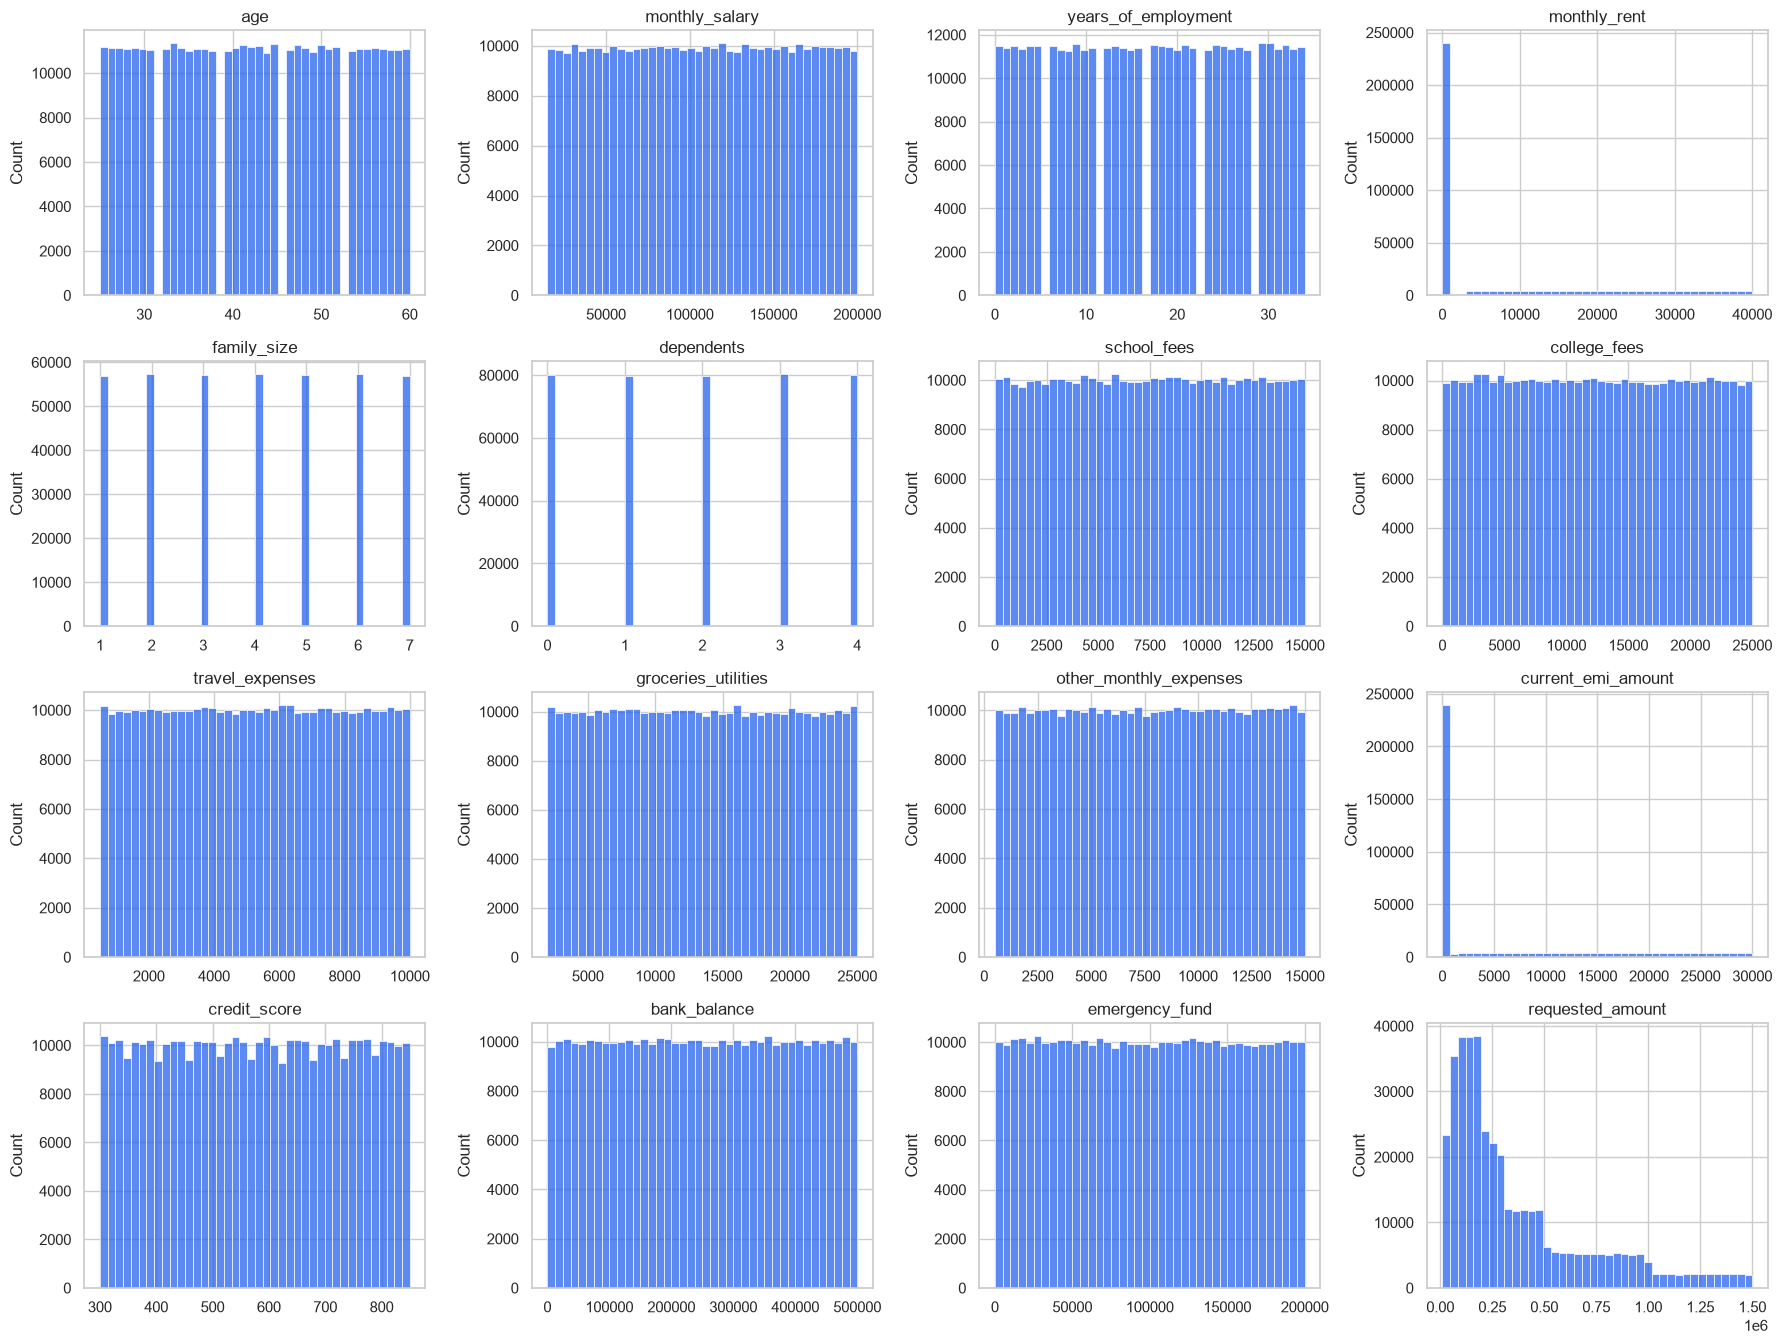

In [8]:
num_cols = [c for c in df.select_dtypes("number").columns if c != TARGET_REG]
cols = num_cols[:16]
rows = int(np.ceil(len(cols) / 4))
fig, axes = plt.subplots(rows, 4, figsize=(18, 3.4 * rows))
for ax, c in zip(np.array(axes).ravel(), cols):
    sns.histplot(df[c], bins=40, ax=ax, color="#2563eb")
    ax.set_title(c); ax.set_xlabel("")
for ax in np.array(axes).ravel()[len(cols):]:
    ax.axis("off")
fig.tight_layout()
save("04_numeric_histograms", "Numeric feature distributions")

In [9]:
rows_out = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows_out.append((c, n_out, round(n_out / len(df) * 100, 2)))
outliers = pd.DataFrame(rows_out, columns=["feature", "outliers", "percent"]).sort_values("percent", ascending=False)
outliers.to_csv("reports/outlier_summary.csv", index=False)
display(outliers.head(10))
top = outliers.head(3)
insights.append("Most outliers (IQR rule): " + ", ".join(f"{r.feature} ({r.percent}%)" for r in top.itertuples())
                + ". Money columns are right-skewed, so scaling is applied in the pipeline.")

,feature,outliers,percent
15,requested_amount,25228,6.31
16,requested_tenure,7555,1.89
11,current_emi_amount,1964,0.49
9,groceries_utilities,0,0.00
14,emergency_fund,0,0.00
13,bank_balance,0,0.00
12,credit_score,0,0.00
10,other_monthly_expenses,0,0.00
0,age,0,0.00
1,monthly_salary,0,0.00


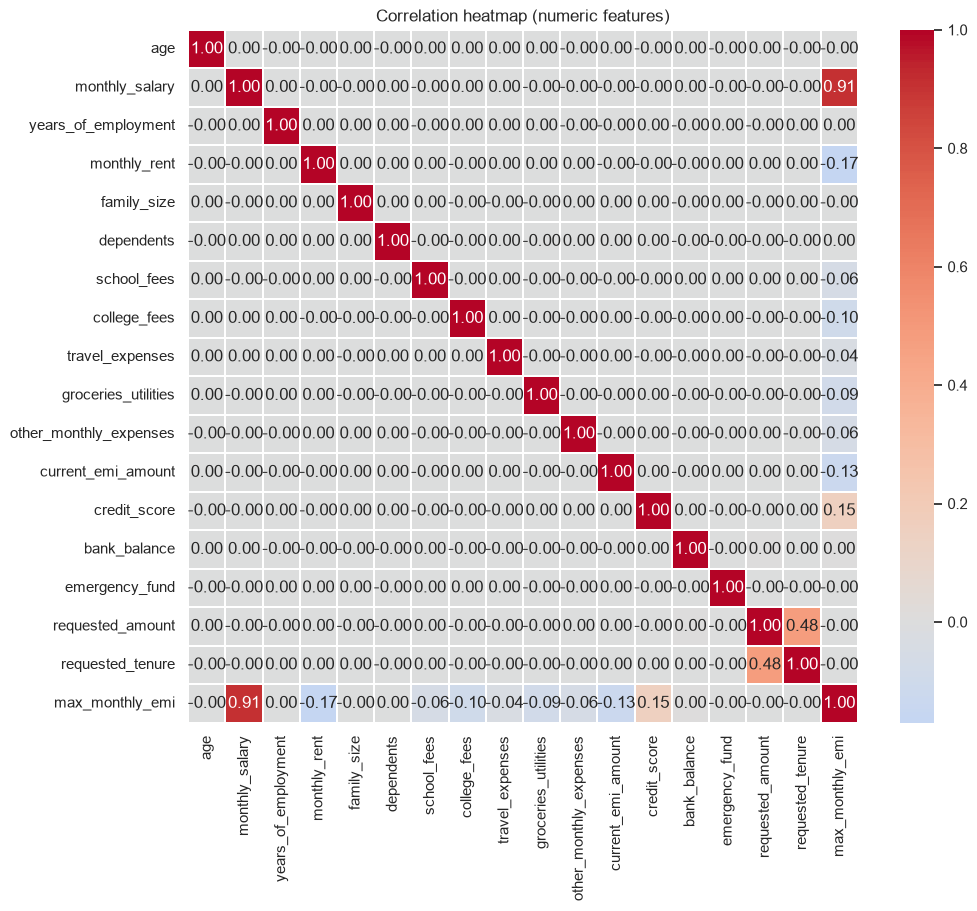

In [10]:
corr = df.select_dtypes("number").corr()
plt.figure(figsize=(max(9, 0.6 * len(corr)), max(7, 0.5 * len(corr))))
sns.heatmap(corr, annot=len(corr) <= 18, fmt=".2f", cmap="coolwarm", center=0, linewidths=.3)
plt.title("Correlation heatmap (numeric features)")
save("05_correlation_heatmap", "Correlation heatmap")

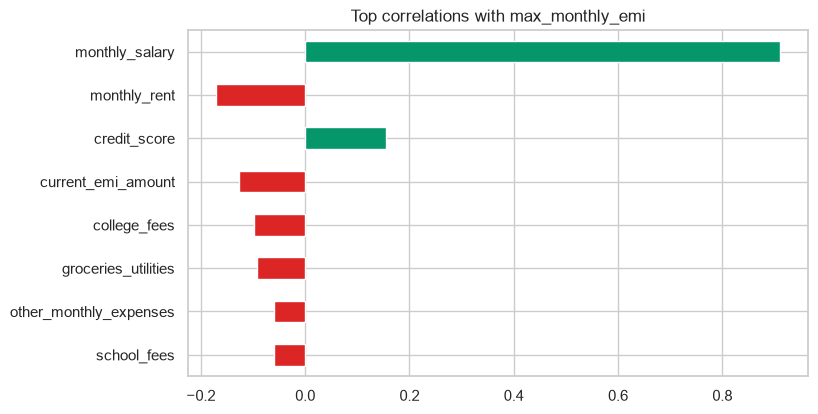

,,correlation
monthly_salary,max_monthly_emi,0.910589


In [11]:
s = corr[TARGET_REG].drop(TARGET_REG).sort_values(key=abs, ascending=False).head(8)
plt.figure(figsize=(8, 4.5))
s[::-1].plot(kind="barh", color=np.where(s[::-1] > 0, "#059669", "#dc2626"))
plt.title("Top correlations with max_monthly_emi")
save("06_corr_with_max_emi", "Correlation with max monthly EMI")
insights.append("Strongest correlations with max_monthly_emi: "
                + ", ".join(f"{k} ({v:+.2f})" for k, v in s.head(5).items()) + ".")

pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
         .loc[lambda x: x.abs() > 0.8].sort_values(key=abs, ascending=False))
if len(pairs):
    insights.append("Highly correlated pairs (|r| > 0.8): "
                    + "; ".join(f"{a} & {b} ({v:+.2f})" for (a, b), v in pairs.head(4).items())
                    + ". Tree models cope with this; linear models may need regularisation.")
display(pairs.head(10).to_frame("correlation"))

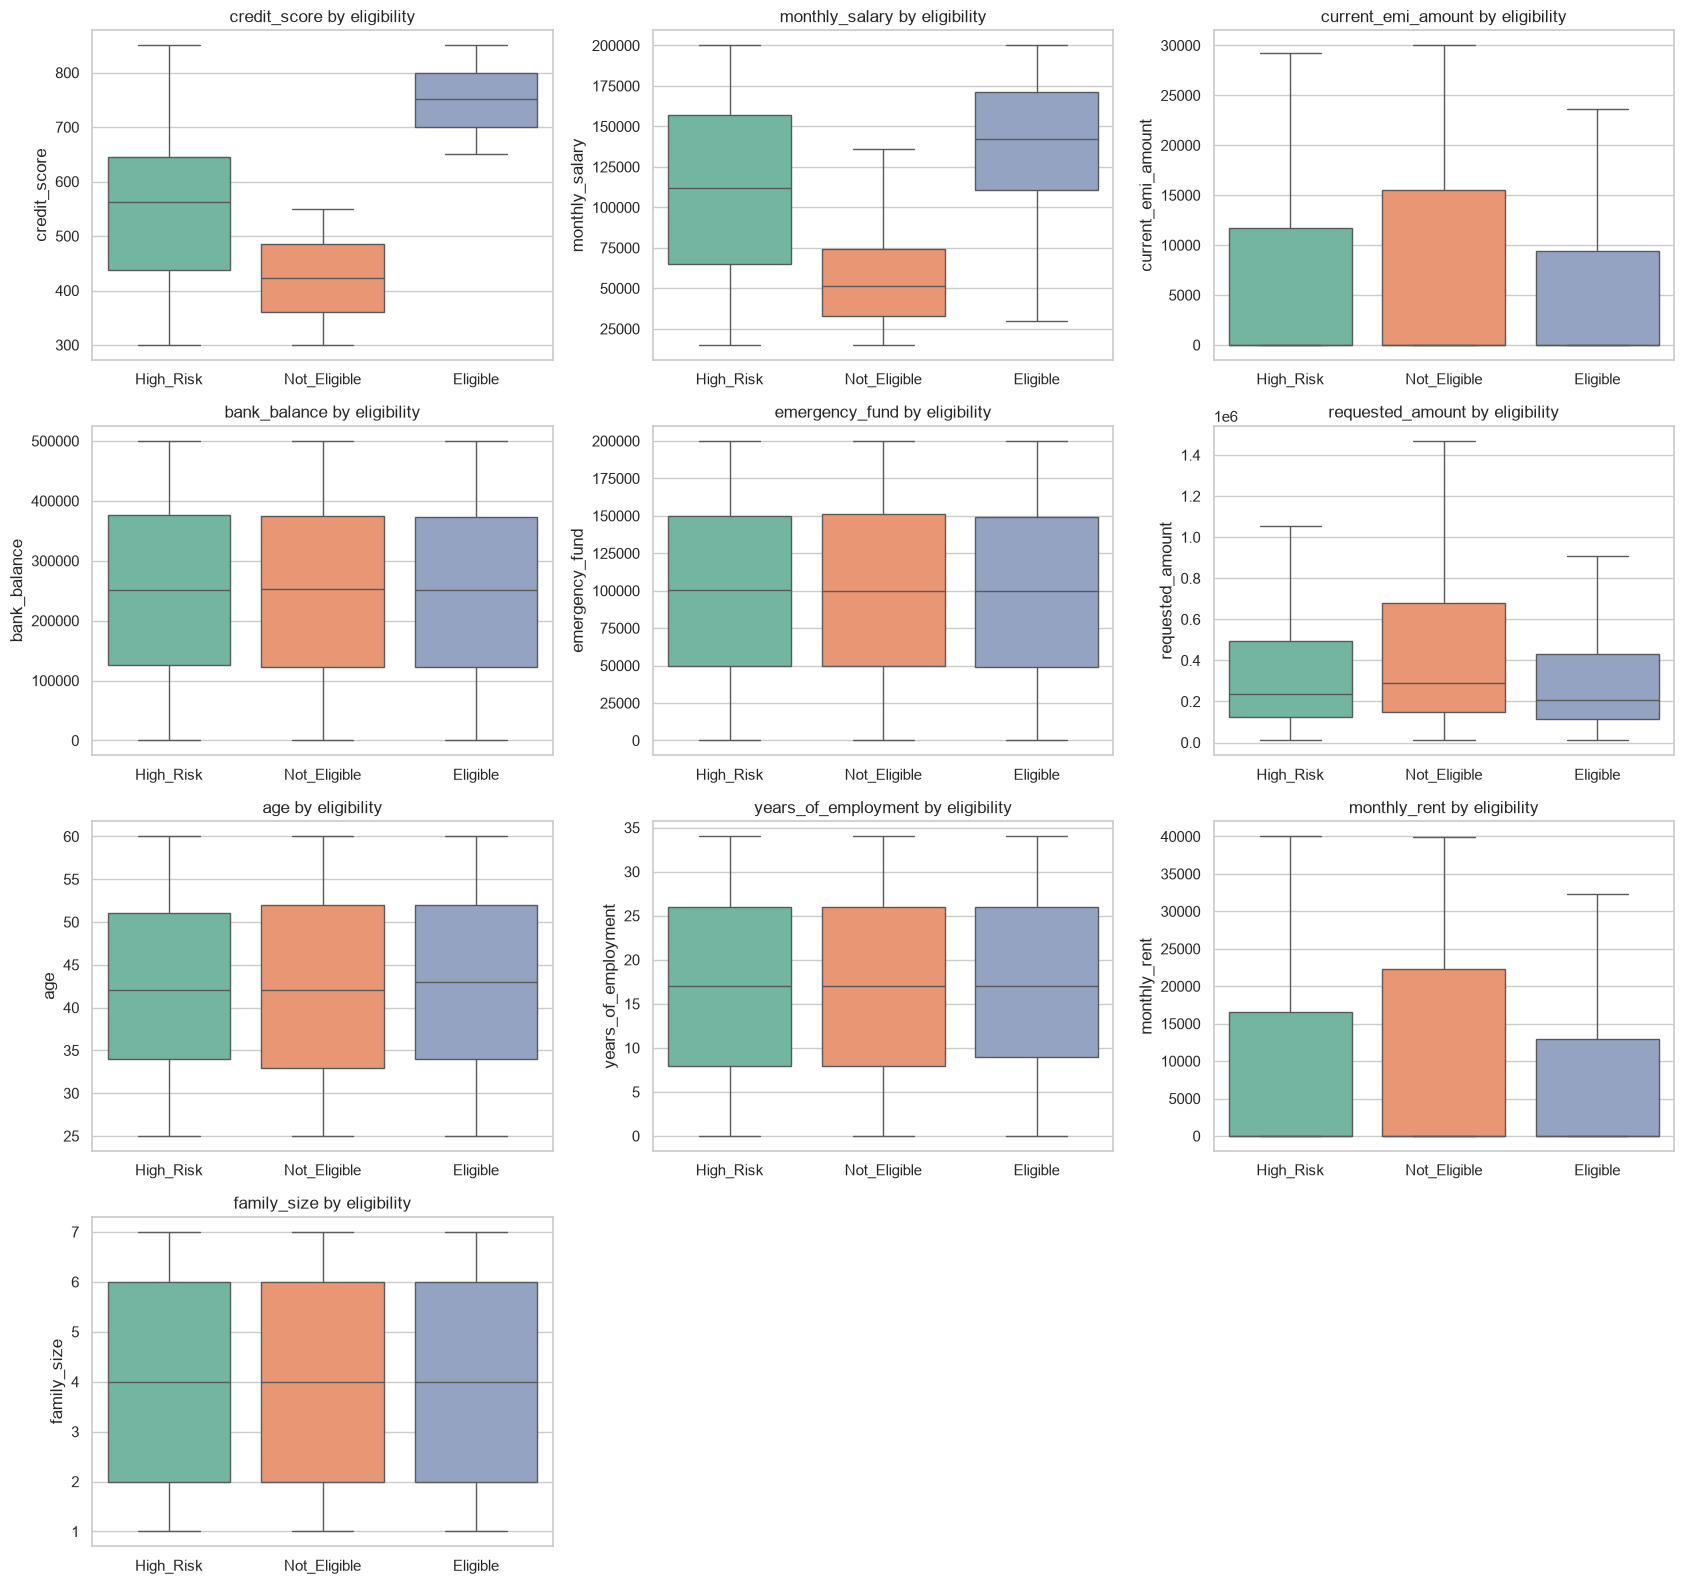

emi_eligibility,Eligible,High_Risk,Not_Eligible
credit_score,751.0,562.0,421.0
monthly_salary,142357.0,111953.0,51298.0
current_emi_amount,0.0,0.0,0.0
bank_balance,251741.0,249382.0,249411.0
emergency_fund,100249.0,99637.0,100089.5
requested_amount,204104.0,235666.0,288048.0
age,42.0,43.0,43.0
years_of_employment,17.0,17.0,17.0
monthly_rent,0.0,0.0,0.0
family_size,4.0,4.0,4.0


In [12]:
sample = df.sample(min(50_000, len(df)), random_state=RANDOM_STATE)
key = [c for c in ["credit_score", "monthly_salary", "current_emi_amount", "bank_balance", "emergency_fund",
                   "existing_loans", "requested_amount", "age", "years_of_employment", "monthly_rent", "family_size"]
       if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
rows = int(np.ceil(len(key) / 3))
fig, axes = plt.subplots(rows, 3, figsize=(17, 4 * rows))
for ax, c in zip(np.array(axes).ravel(), key):
    sns.boxplot(data=sample, x=TARGET_CLF, y=c, ax=ax, showfliers=False, palette="Set2")
    ax.set_title(f"{c} by eligibility"); ax.set_xlabel("")
for ax in np.array(axes).ravel()[len(key):]:
    ax.axis("off")
fig.tight_layout()
save("07_risk_factors_boxplots", "Key numeric risk factors by eligibility")

med = df.groupby(TARGET_CLF)[key].median().round(1)
display(med.T)
for c in ("credit_score", "monthly_salary", "current_emi_amount"):
    if c in med.columns:
        insights.append(f"Median {c} by class: "
                        + ", ".join(f"{k} = {v:,.0f}" for k, v in med[c].sort_values().items()) + ".")

emi_eligibility,Eligible,High_Risk,Not_Eligible
credit_score,,,
<600,0.0,68.4,31.6
600-699,30.2,69.8,0.0
700-749,60.0,40.0,0.0
750+,60.3,39.7,0.0


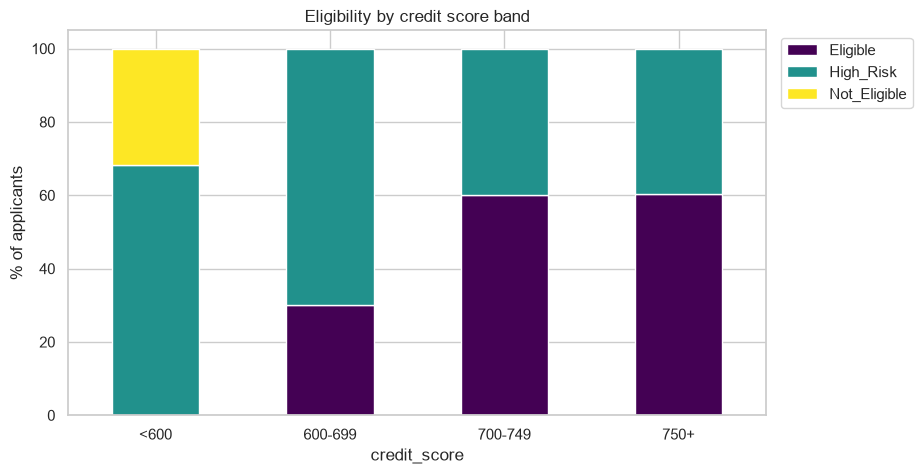

In [13]:
if "credit_score" in df.columns:
    bands = pd.cut(df["credit_score"], [-np.inf, 600, 700, 750, np.inf], labels=["<600", "600-699", "700-749", "750+"])
    ct = pd.crosstab(bands, df[TARGET_CLF], normalize="index") * 100
    display(ct.round(1))
    ct.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="viridis")
    plt.ylabel("% of applicants"); plt.xticks(rotation=0)
    plt.title("Eligibility by credit score band")
    plt.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")
    save("08_credit_band_eligibility", "Eligibility by credit score band")
    good = df[TARGET_CLF].value_counts().index[0]
    insights.append(f"Credit score is a major driver: the share of '{good}' goes from "
                    f"{ct.loc[ct.index[0], good]:.1f}% (score {ct.index[0]}) to {ct.loc[ct.index[-1], good]:.1f}% (score {ct.index[-1]}).")

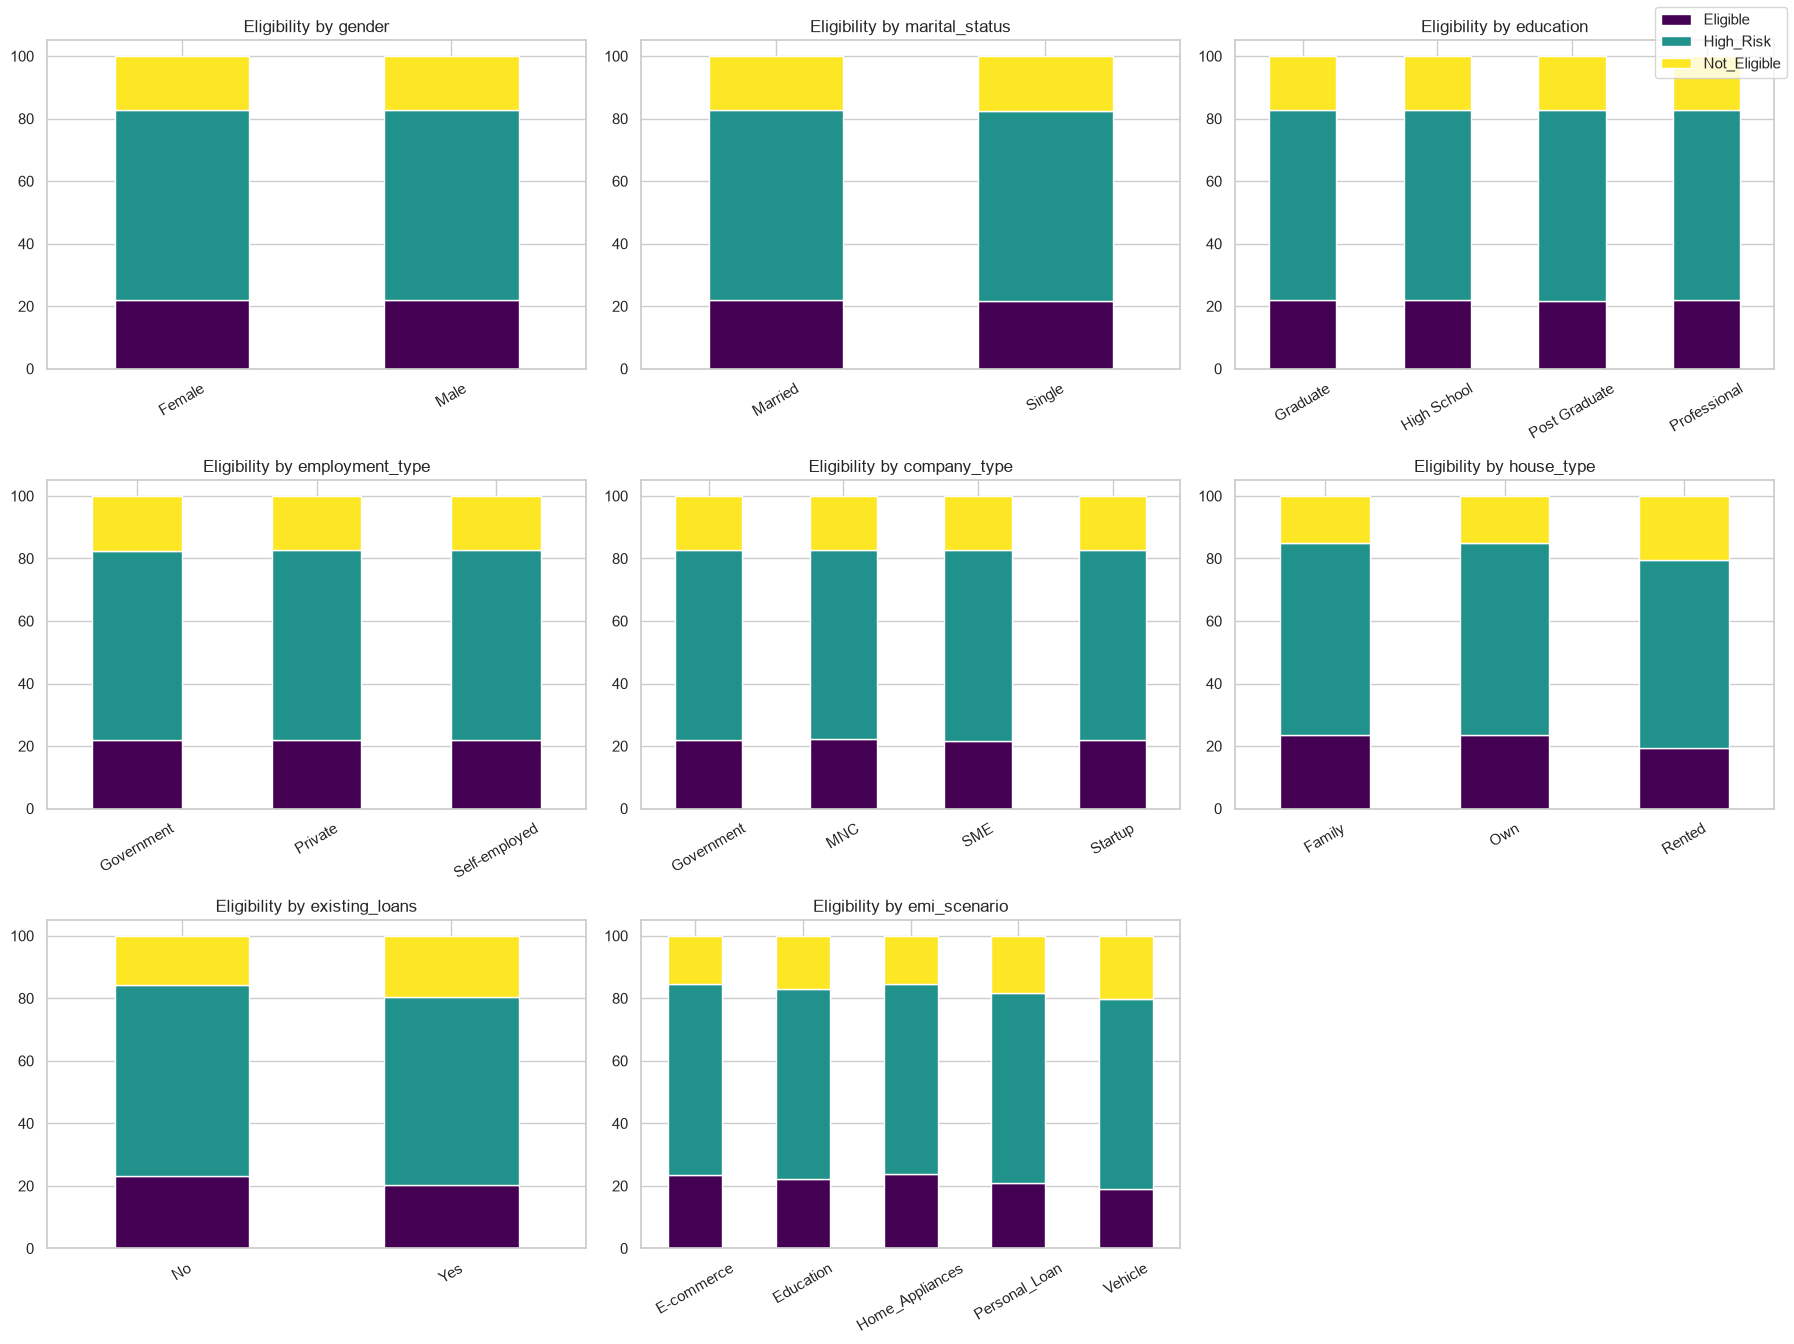

In [14]:
cats = [c for c in df.select_dtypes("object").columns if c != TARGET_CLF and df[c].nunique() <= 12]
if cats:
    rows = int(np.ceil(len(cats) / 3))
    fig, axes = plt.subplots(rows, 3, figsize=(18, 4.5 * rows))
    for ax, c in zip(np.array(axes).ravel(), cats):
        ct = pd.crosstab(df[c], df[TARGET_CLF], normalize="index") * 100
        ct.plot(kind="bar", stacked=True, ax=ax, colormap="viridis", legend=False)
        ax.set_title(f"Eligibility by {c}"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
    for ax in np.array(axes).ravel()[len(cats):]:
        ax.axis("off")
    h, l = np.array(axes).ravel()[0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper right")
    fig.tight_layout()
    save("09_categorical_vs_eligibility", "Categorical features vs eligibility")

    good = df[TARGET_CLF].value_counts().index[0]
    for c in cats:
        ct = pd.crosstab(df[c], df[TARGET_CLF], normalize="index") * 100
        if ct[good].max() - ct[good].min() > 5:
            insights.append(f"'{c}' matters: the share of {good} ranges from {ct[good].min():.1f}% ({ct[good].idxmin()}) "
                            f"to {ct[good].max():.1f}% ({ct[good].idxmax()}).")

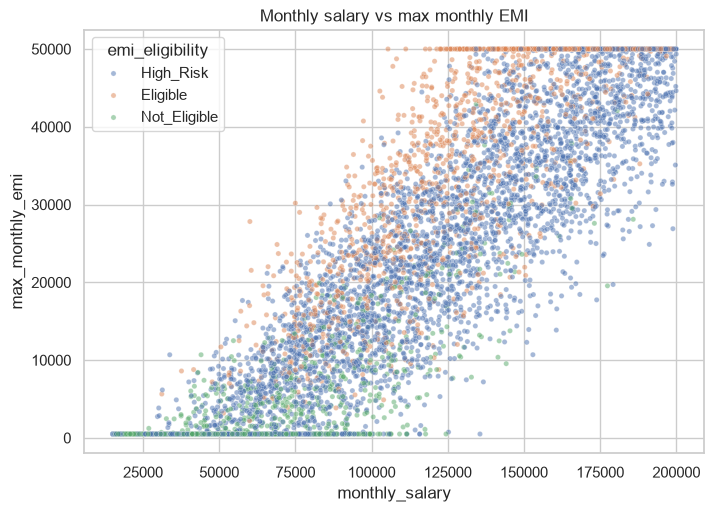

In [15]:
if "monthly_salary" in df.columns:
    plt.figure(figsize=(8, 5.5))
    sns.scatterplot(data=sample.sample(min(8000, len(sample)), random_state=1),
                    x="monthly_salary", y=TARGET_REG, hue=TARGET_CLF, alpha=.5, s=14)
    plt.title("Monthly salary vs max monthly EMI")
    save("10_salary_vs_max_emi", "Salary vs max monthly EMI")

In [16]:
for i, t in enumerate(insights, 1):
    print(f"{i}. {t}\n")

1. The dataset has 400,000 records and 27 columns (200 duplicates removed, 4,000 missing cells handled later by the pipeline's imputers).

2. Class balance: High_Risk = 60.8%, Eligible = 21.8%, Not_Eligible = 17.3%. The classes are imbalanced, so classifiers should use class weights and be judged on F1 / recall, not accuracy alone.

3. max_monthly_emi ranges from 500 to 50,000 (median 20,070, mean 22,157, skew 0.23).

4. Eligibility differs by scenario: 'E-commerce' has the highest share of High_Risk (61.0%) and 'Personal_Loan' the lowest (60.6%).

5. Most outliers (IQR rule): requested_amount (6.31%), requested_tenure (1.89%), current_emi_amount (0.49%). Money columns are right-skewed, so scaling is applied in the pipeline.

6. Strongest correlations with max_monthly_emi: monthly_salary (+0.91), monthly_rent (-0.17), credit_score (+0.15), current_emi_amount (-0.13), college_fees (-0.10).

7. Highly correlated pairs (|r| > 0.8): monthly_salary & max_monthly_emi (+0.91). Tree models cop

### My own conclusions (write 3-4 lines in your own words after reading the charts)
- Applicants with a low credit score are mostly ...
- Higher expenses and existing EMIs reduce ...
- The scenario with the highest / lowest eligibility is ... because ...

# STEP 3 - Feature Engineering
The logic lives in `feature_engineering.py` so that Members 3, 4 and 5 can load the saved pipeline.

| Type | Features |
|---|---|
| Ratios | debt_to_income, expense_to_income, total_obligation_ratio, affordability_ratio, savings_to_income, emergency_cushion_months, income_per_family_member, employment_stability, requested_emi_to_income, requested_emi_to_disposable |
| Interactions | credit_x_income, credit_x_affordability, dti_x_expense_ratio, credit_x_dti |
| Encoding | One-Hot encoding for every categorical column |
| Scaling | StandardScaler for every numeric column |
| Missing values | Median (numeric), most frequent (categorical) |

In [17]:
X_raw = df.drop(columns=[TARGET_CLF, TARGET_REG])
eng = FeatureEngineer().fit(X_raw).transform(X_raw)
new_cols = [c for c in eng.columns if c not in X_raw.columns]
print(f"{len(new_cols)} new features:", new_cols)
display(eng[new_cols].describe().T.round(3))

17 new features: ['total_monthly_expenses', 'debt_to_income', 'expense_to_income', 'total_obligation_ratio', 'disposable_income', 'affordability_ratio', 'savings_to_income', 'emergency_cushion_months', 'income_per_family_member', 'employment_stability', 'requested_emi_estimate', 'requested_emi_to_disposable', 'requested_emi_to_income', 'credit_x_income', 'credit_x_affordability', 'dti_x_expense_ratio', 'credit_x_dti']


,count,mean,std,min,25%,50%,75%,max
total_monthly_expenses,400000.0,5.508736e+04,1.721689e+04,6017.000,4.266000e+04,5.324500e+04,6.589300e+04,1.223430e+05
debt_to_income,396000.0,8.700000e-02,1.840000e-01,0.000,0.000000e+00,0.000000e+00,1.100000e-01,1.960000e+00
expense_to_income,396000.0,7.700000e-01,7.180000e-01,0.038,3.410000e-01,5.110000e-01,8.980000e-01,7.190000e+00
total_obligation_ratio,396000.0,8.570000e-01,8.020000e-01,0.044,3.790000e-01,5.690000e-01,1.000000e+00,8.337000e+00
disposable_income,396000.0,4.630433e+04,5.686933e+04,-118212.000,1.100000e+01,4.642550e+04,9.263800e+04,1.879270e+05
affordability_ratio,396000.0,1.430000e-01,8.020000e-01,-7.337,0.000000e+00,4.310000e-01,6.210000e-01,9.560000e-01
savings_to_income,396000.0,4.889000e+00,4.975000e+00,0.009,1.989000e+00,3.255000e+00,5.720000e+00,4.479700e+01
emergency_cushion_months,400000.0,1.824000e+00,1.323000e+00,0.000,8.130000e-01,1.628000e+00,2.542000e+00,2.245100e+01
income_per_family_member,396000.0,3.984602e+04,3.908018e+04,2143.000,1.535350e+04,2.689088e+04,4.761775e+04,1.999990e+05
employment_stability,400000.0,4.270000e-01,2.860000e-01,0.000,1.940000e-01,4.000000e-01,6.090000e-01,1.360000e+00


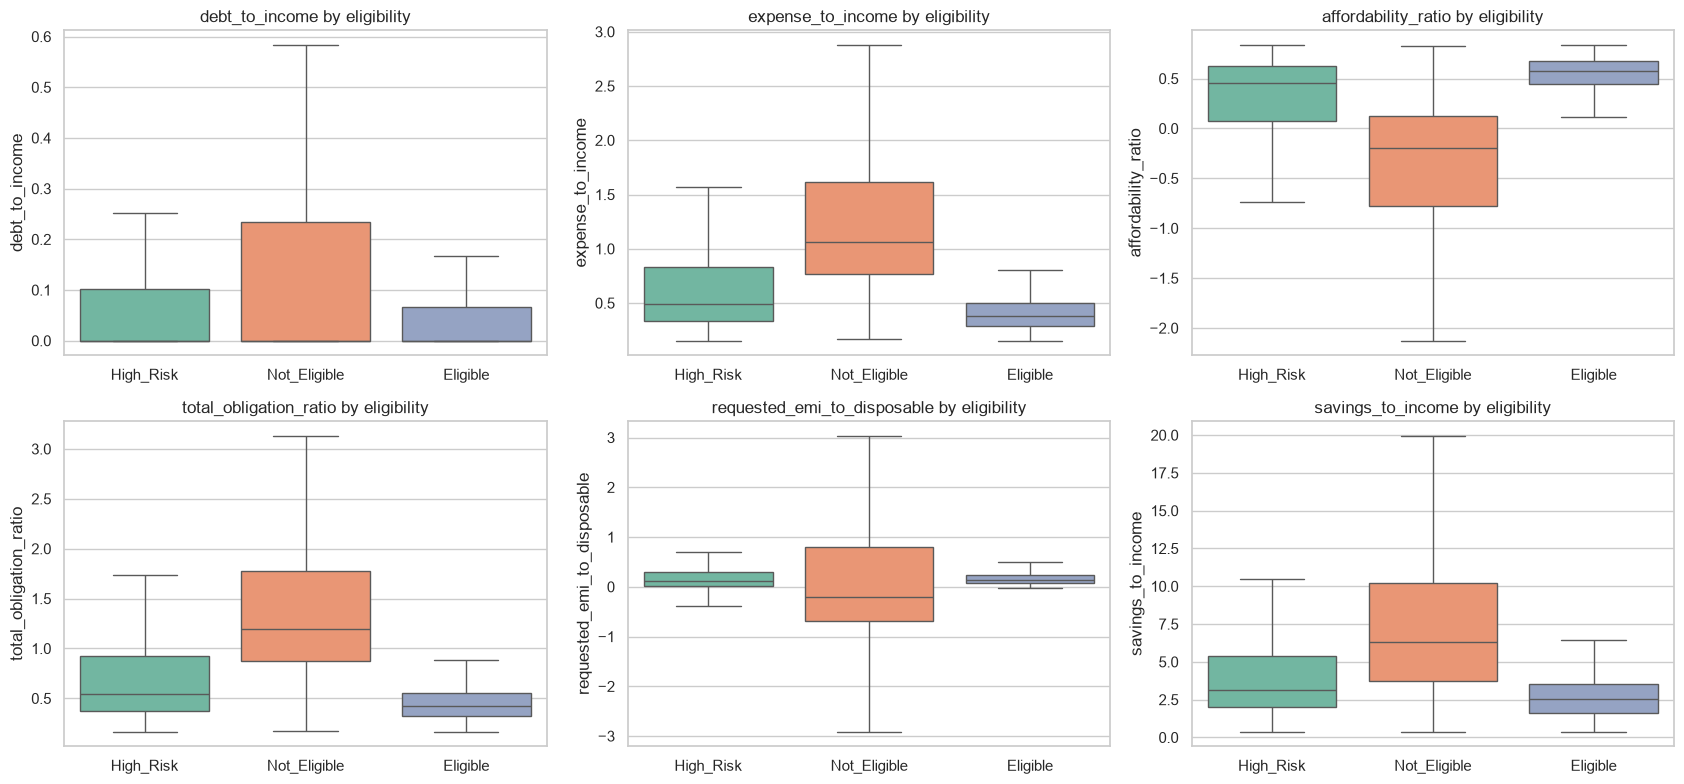

In [18]:
chk = eng[new_cols].copy()
chk[TARGET_CLF] = df[TARGET_CLF].values
chk[TARGET_REG] = df[TARGET_REG].values
smp = chk.sample(min(50_000, len(chk)), random_state=RANDOM_STATE)

show = [c for c in ["debt_to_income", "expense_to_income", "affordability_ratio",
                    "total_obligation_ratio", "requested_emi_to_disposable", "savings_to_income"] if c in new_cols]
rows = int(np.ceil(len(show) / 3))
fig, axes = plt.subplots(rows, 3, figsize=(17, 4 * rows))
for ax, c in zip(np.array(axes).ravel(), show):
    lo, hi = smp[c].quantile([.01, .99])
    sns.boxplot(data=smp[(smp[c] >= lo) & (smp[c] <= hi)], x=TARGET_CLF, y=c, ax=ax, showfliers=False, palette="Set2")
    ax.set_title(f"{c} by eligibility"); ax.set_xlabel("")
for ax in np.array(axes).ravel()[len(show):]:
    ax.axis("off")
fig.tight_layout()
save("11_engineered_ratios", "Engineered ratios by eligibility")

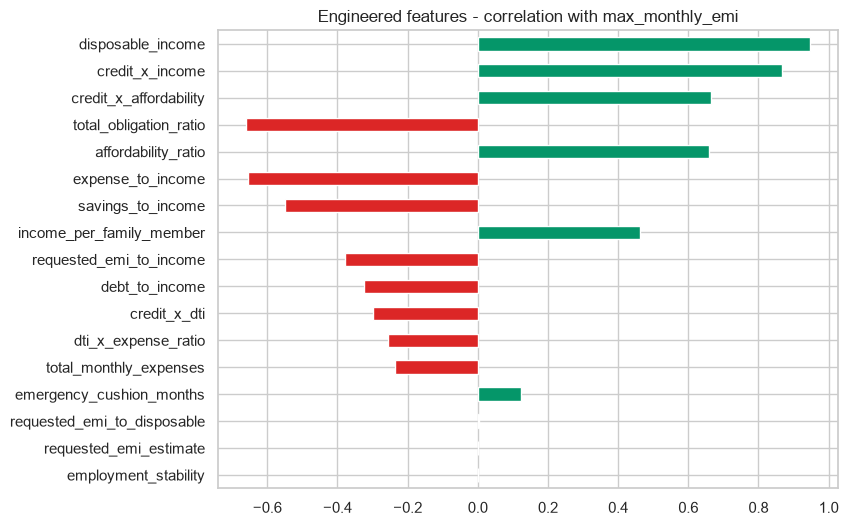

In [19]:
ec = chk[new_cols + [TARGET_REG]].corr()[TARGET_REG].drop(TARGET_REG).sort_values(key=abs, ascending=False)
plt.figure(figsize=(8, max(4, 0.35 * len(ec))))
ec[::-1].plot(kind="barh", color=np.where(ec[::-1] > 0, "#059669", "#dc2626"))
plt.title("Engineered features - correlation with max_monthly_emi")
save("12_engineered_corr_max_emi", "Engineered features vs max monthly EMI")

insights.append(f"{len(new_cols)} new features were engineered (ratios and interactions). Most related to max_monthly_emi: "
                + ", ".join(f"{k} ({v:+.2f})" for k, v in ec.head(4).items()) + ".")
for c in ("debt_to_income", "expense_to_income", "affordability_ratio"):
    if c in new_cols:
        m = chk.groupby(TARGET_CLF)[c].median()
        insights.append(f"Median {c} by class: " + ", ".join(f"{k} = {v:.2f}" for k, v in m.sort_values().items()) + ".")

In [20]:
X_train, X_test = train_test_split(X_raw, test_size=0.2, random_state=RANDOM_STATE, stratify=df[TARGET_CLF])

pipe = build_pipeline()
pipe.fit(X_train)

Xt_train = pipe.transform(X_train)
Xt_test = pipe.transform(X_test)
feature_names = list(pipe.get_feature_names_out())

print("Input columns :", X_raw.shape[1])
print("Output features:", len(feature_names))
print("Train shape   :", Xt_train.shape, "| Test shape:", Xt_test.shape)
print("NaN left      :", int(np.isnan(Xt_train).sum()))
pd.DataFrame(Xt_train[:5], columns=feature_names).round(3)

Input columns : 25
Output features: 59
Train shape   : (320000, 59) | Test shape: (80000, 59)
NaN left      : 0


,age,monthly_salary,years_of_employment,monthly_rent,family_size,dependents,school_fees,college_fees,travel_expenses,groceries_utilities,other_monthly_expenses,current_emi_amount,credit_score,bank_balance,emergency_fund,requested_amount,requested_tenure,total_monthly_expenses,debt_to_income,expense_to_income,total_obligation_ratio,disposable_income,affordability_ratio,savings_to_income,emergency_cushion_months,...,gender_Female,gender_Male,marital_status_Married,marital_status_Single,education_Graduate,education_High School,education_Post Graduate,education_Professional,employment_type_Government,employment_type_Private,employment_type_Self-employed,company_type_Government,company_type_MNC,company_type_SME,company_type_Startup,house_type_Family,house_type_Own,house_type_Rented,existing_loans_No,existing_loans_Yes,emi_scenario_E-commerce,emi_scenario_Education,emi_scenario_Home_Appliances,emi_scenario_Personal_Loan,emi_scenario_Vehicle
0,-1.684,-0.963,-0.594,-0.687,1.001,1.414,-1.154,0.080,0.476,0.770,-0.336,-0.670,1.075,-1.519,0.777,2.287,2.268,-0.464,-0.470,0.092,-0.026,-0.652,0.026,-0.356,0.946,...,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.916,1.210,-0.001,-0.687,1.501,-1.414,0.691,0.755,0.286,0.175,-0.751,-0.506,0.993,0.185,-0.062,-0.639,-1.000,-0.079,-0.421,-0.637,-0.668,1.243,0.668,-0.546,-0.061,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,0.435,-0.012,-1.286,1.091,-1.502,1.414,-0.955,1.505,-0.735,0.060,1.049,-0.670,-1.213,-1.641,0.221,-0.048,-0.446,1.345,-0.470,-0.051,-0.154,-0.311,0.154,-0.747,-0.290,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,-0.625,-1.594,0.593,2.085,-1.001,-0.000,-0.604,-1.142,1.368,0.876,0.556,0.589,-0.484,-1.267,-0.496,0.092,2.324,1.575,2.304,3.941,4.054,-2.072,-4.054,0.235,-0.805,...,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.820,-0.673,-1.484,1.350,-1.502,-1.414,-0.614,0.213,-0.139,-0.082,1.075,0.993,0.239,1.679,0.969,-0.539,-0.502,1.123,0.700,0.376,0.496,-1.136,-0.496,0.840,-0.066,...,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [21]:
joblib.dump(pipe, "feature_pipeline.pkl")
with open("feature_names.json", "w") as f:
    json.dump({"input_columns": list(X_raw.columns),
               "output_features": feature_names,
               "n_output_features": len(feature_names)}, f, indent=2)

# reload test - exactly how Members 3, 4 and 5 will use it
loaded = joblib.load("feature_pipeline.pkl")
assert np.allclose(loaded.transform(X_test.head(10)), Xt_test[:10])
print("feature_pipeline.pkl saved and reload test passed")

insights.append(f"Final pipeline: feature engineering, then median imputation + StandardScaler (numeric) and "
                f"mode imputation + One-Hot encoding (categorical). It turns {X_raw.shape[1]} raw columns into "
                f"{len(feature_names)} model-ready features and was fitted on the training split only.")

feature_pipeline.pkl saved and reload test passed


**How other members use it**
```python
import joblib
from feature_engineering import FeatureEngineer      # required for loading the pickle
pipe = joblib.load("feature_pipeline.pkl")
X_ready = pipe.transform(raw_dataframe)               # raw columns only, no target columns
```

In [22]:
from docx import Document
from docx.shared import Inches

doc = Document()
doc.add_heading("EMI Predict AI - EDA & Feature Engineering Report", 0)
doc.add_paragraph("Member 2 - EDA & Feature Engineer")

doc.add_heading("1. Key insights", 1)
for t in insights:
    doc.add_paragraph(t, style="List Number")

doc.add_heading("2. Feature engineering summary", 1)
doc.add_paragraph("Ratios: debt_to_income, expense_to_income, total_obligation_ratio, affordability_ratio, "
                  "savings_to_income, emergency_cushion_months, income_per_family_member, employment_stability, "
                  "requested_emi_to_income, requested_emi_to_disposable.")
doc.add_paragraph("Interactions: credit_x_income, credit_x_affordability, dti_x_expense_ratio, credit_x_dti.")
doc.add_paragraph("Encoding: One-Hot. Scaling: StandardScaler. Missing values: median / most frequent.")

doc.add_heading("3. Visuals", 1)
for title, path in charts:
    doc.add_heading(title, 2)
    doc.add_picture(path, width=Inches(6.2))

doc.save("reports/EDA_Report.docx")
print("saved reports/EDA_Report.docx")

saved reports/EDA_Report.docx
